# Direct pooled bounded-drift test: fresh comparison
## tl;dr
For the predeclared **plan 9, balanced 1% raw-bit floor probe with zero
allowed drift**, the direct rule detects **168/512
(32.81%)**, versus CP **22/512
(4.30%)** on identical new public pairs. The saved paired
interval for that improvement excludes zero. This is pointwise evidence,
not continuous worst-case power, equal attained FPR or final-key security.

At half the overlap-boundary allowance, direct detects only
**12/512 (2.34%)**. The method is stronger
in some tested settings but weak-drift sensitivity remains inadequate.
Population overlap is unchanged. Standard CP, Bernstein and Hoeffding tools
are not discoveries of this project; publication novelty remains unverified.

## Context & Methods
Read the [complete derivation](../docs/direct-drift-test.md),
[frozen comparison](../docs/direct-drift-protocol.md) and
[approved physical model](../docs/bounded-drift-model.md).
The new rule pools equal-probability preparation bits within each basis,
directly concentrates the difference, and budgets a CP variance-envelope
failure event. It tests both signs and keeps separate stable-gain checks.
It is not a known-noise oracle, plug-in normal approximation or exact nuisance optimizer.

### Key Assumptions
Independent blockwise iid stages; genuinely attack-free trusted calibration;
common per-basis bit error probabilities in [0,.5]; error-independent
selection; stable gains and predeclared absolute per-basis allowances.
The attacked baseline retains fixed lambda=.03. Concurrent attack/drift,
general quantum attacks, repeated peeking and changing gains are outside scope.
All three detectors have separate alpha=.05 upper guarantees; their
attained honest false-alarm rates need not be equal. No OR across rules is scored.

Fresh seed 2026100912, 216 cohorts × 512 pairs, 4 million emissions per
pair, two fixed allocations with equal expected sacrifice/candidates.
The raw-bit proxy r/2 is not mutual information or final-key leakage.
The new design uses standard tools and does not imply publication priority.
Setup uses [requirements-notebooks.txt](../requirements-notebooks.txt).
Build with `python quantum-ai-lab/scripts/build_direct_drift_notebook.py`.
This notebook reads frozen evidence and recreates figures, not simulation results.

## Data
### 1. Verify the evidence
Sources: `results/benchmarks/direct-drift-pilot-v1/pilot.json`,
`public_counts.csv.gz`, `audit.json`. The audit replays every saved
decision and regenerates every count from its seed. Scalar checks cover
fixed first/middle/last rows; CP references still share SciPy.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image, display
root = next(p for p in [Path.cwd(), Path.cwd()/'quantum-ai-lab', Path.cwd().parent]
            if (p/'src/research/direct_drift_detector.py').is_file())
evidence = root/'results/benchmarks/direct-drift-pilot-v1'
result = json.loads((evidence/'pilot.json').read_text())
audit = json.loads((evidence/'audit.json').read_text())
for rel, digest in result['source_sha256'].items():
    assert hashlib.sha256((root/rel).read_bytes()).hexdigest() == digest
for rel, digest in result['output_sha256'].items():
    assert hashlib.sha256((evidence/rel).read_bytes()).hexdigest() == digest
assert result['public_pairs']==110592 and audit['status']=='passed'
assert audit['decision_replays']==331776
keys = ('plan_id','floor_id','allowance_id','cohort_id','method')
rates = {tuple(c[k] for k in keys):c for c in result['cells']}
effects = {tuple(e[k] for k in keys[:-1]):e for e in result['effects']}
assert len(rates)==648 and len(effects)==216
figures = root/'docs/figures/direct-drift-pilot-v1'
figures.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size':11, 'axes.spines.top':False,
                     'axes.spines.right':False, 'figure.dpi':120})
styles = {'hoeffding':('#777777','s',':'), 'clopper-pearson':('#245b87','o','-'),
          'direct-bernstein':('#9a7027','D','--')}
labels = {'hoeffding':'Hoeffding gap', 'clopper-pearson':'CP gap',
          'direct-bernstein':'Direct pooled'}
def show(fig, name, alt):
    fig.savefig(figures/name, dpi=150, bbox_inches='tight')
    display(Image(filename=str(figures/name), alt=alt))
    plt.close(fig)
print('Frozen versions:', result['versions'])
print('Pairs:', result['public_pairs'], '| Decision replays:', audit['decision_replays'])
print('Joint uncertainty: .04 across 648 rate cells + .01 across 216 paired effects.')

Matplotlib is building the font cache; this may take a moment.


Frozen versions: {'python': '3.12.14', 'numpy': '2.5.3', 'scipy': '1.18.1'}
Pairs: 110592 | Decision replays: 331776
Joint uncertainty: .04 across 648 rate cells + .01 across 216 paired effects.


### 2. Resource reconciliation
These expected counts are raw candidates, not a secure-key length or equal
hardware cost. Realized mean counts use the fixed nominal honest cohort.

In [2]:
for plan in result['protocol']['plans']:
    c = rates[(plan['id'],1,0,0,'direct-bernstein')]
    print(f"Plan {plan['id']}: calibration M={plan['calibration_emitted']:,}; monitoring f={plan['monitoring_disclosure']:.6f}")
    print(f"  expected sacrifice {plan['total_sacrificed']:.2f}; observed mean {c['mean_calibration_sacrificed']+c['mean_monitoring_disclosed']:.2f}")
    print(f"  expected candidates {plan['remaining_candidates']:.2f}; observed mean {c['mean_remaining_candidates']:.2f}")
assert np.isclose(result['protocol']['plans'][0]['remaining_candidates'],
                  result['protocol']['plans'][1]['remaining_candidates'])

Plan 9: calibration M=800,000; monitoring f=0.375000
  expected sacrifice 43572.29; observed mean 43590.55
  expected candidates 43572.29; observed mean 43568.45
Plan 10: calibration M=1,333,333; monitoring f=0.250000
  expected sacrifice 43572.29; observed mean 43566.87
  expected candidates 43572.29; observed mean 43581.50


## Results
### 3. Balanced floor attack probes
Each point uses 512 pairs; error bars are the saved joint rate intervals.
Combined with the paired-effect intervals, coverage is at least 95% across
the full frozen collection, in real arithmetic. This measures Monte Carlo
uncertainty, not device fluctuation. Lines connect declared scenarios only.
The vertical line marks the unchanged population-overlap boundary.

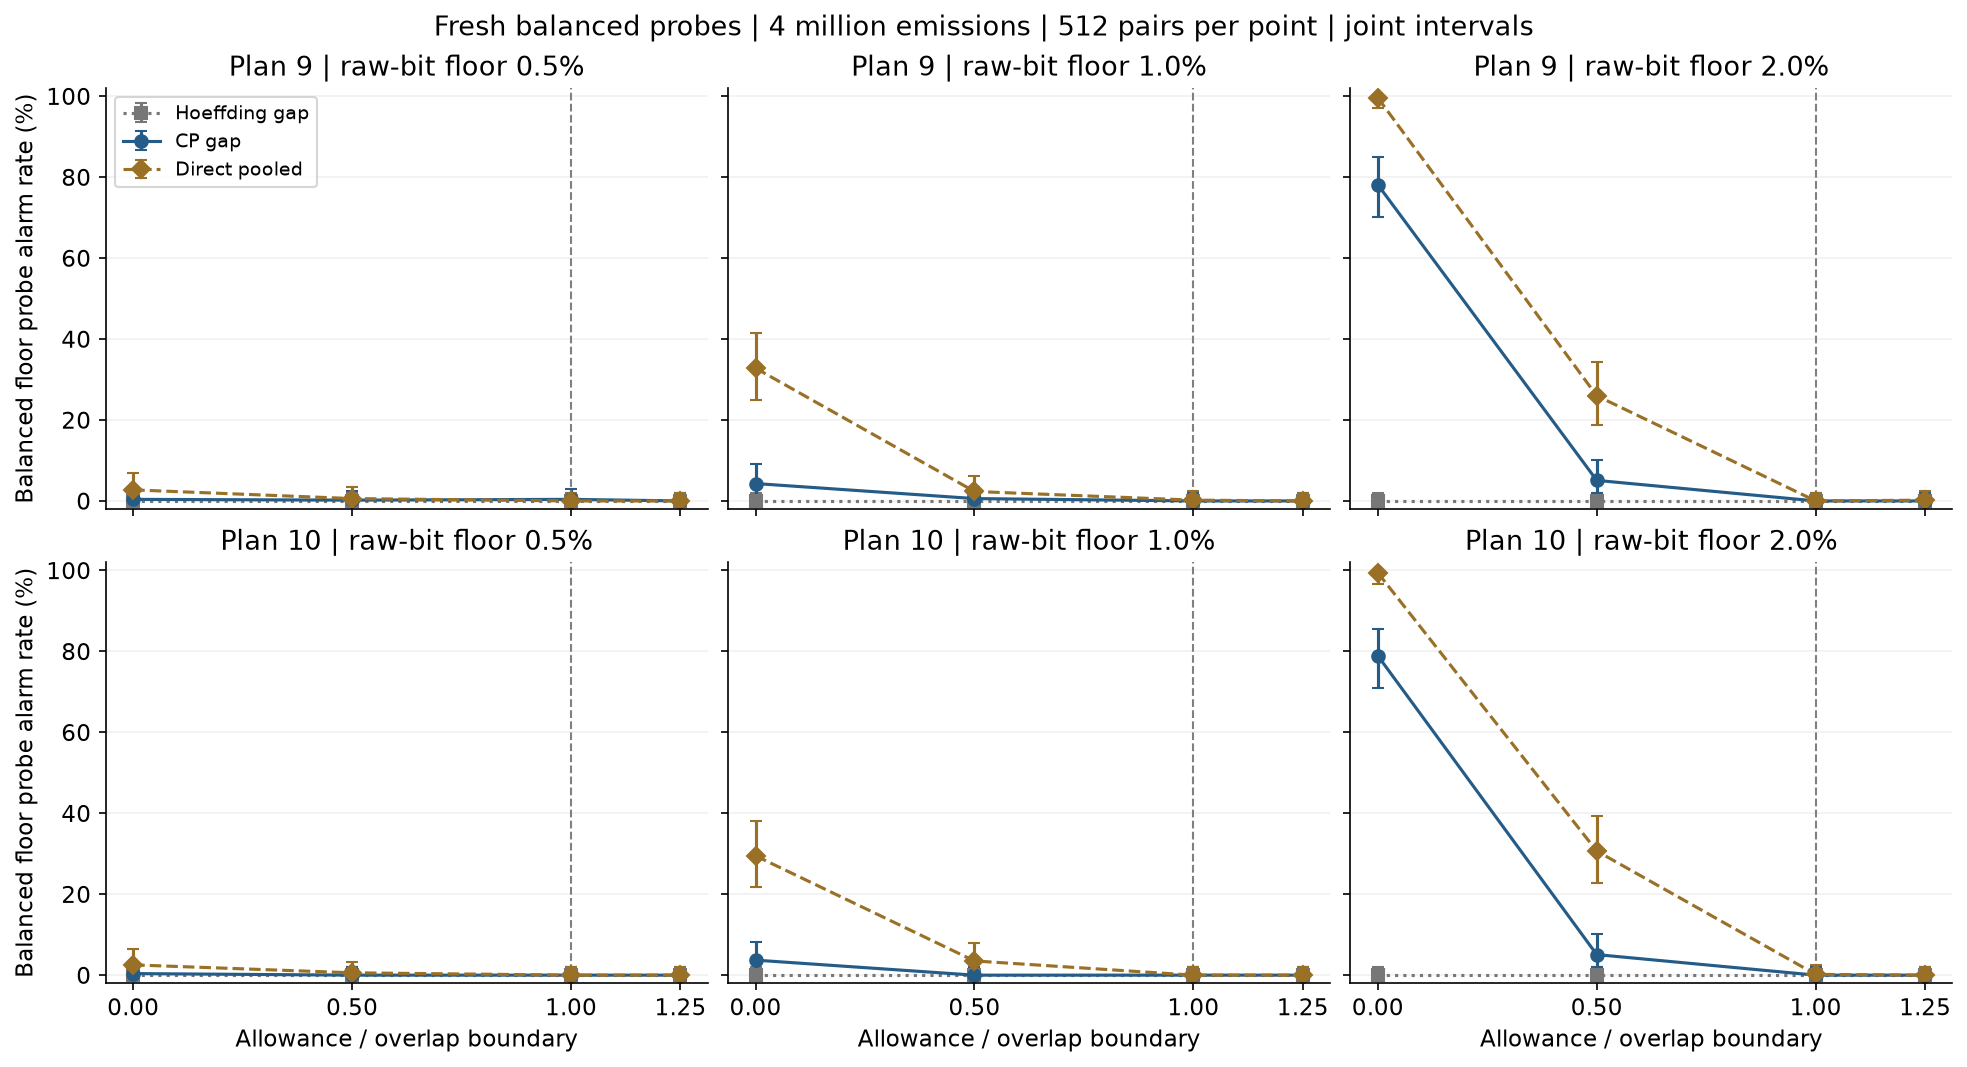

In [3]:
x = np.array(result['protocol']['drift_multipliers'])
fig, axes = plt.subplots(2,3, figsize=(13,7), sharex=True, sharey=True, layout='constrained')
for row, plan in enumerate((9,10)):
    for fi, floor in enumerate(result['protocol']['floors']):
        ax = axes[row,fi]
        for method in result['protocol']['methods']:
            selected = [rates[(plan,fi,a,7,method)] for a in range(4)]
            y = np.array([c['alarm_rate'] for c in selected])*100
            low = np.array([c['ci_joint95'][0] for c in selected])*100
            high = np.array([c['ci_joint95'][1] for c in selected])*100
            color, marker, line = styles[method]
            ax.errorbar(x,y,yerr=[y-low,high-y], color=color, marker=marker,
                        linestyle=line, capsize=3, label=labels[method])
        ax.axvline(1, color='0.5', linestyle='--', linewidth=1)
        ax.set_title(f'Plan {plan} | raw-bit floor {floor:.1%}')
        ax.set_ylim(-2,102); ax.set_xticks(x); ax.grid(axis='y',alpha=.18)
        if fi==0: ax.set_ylabel('Balanced floor probe alarm rate (%)')
        if row==1: ax.set_xlabel('Allowance / overlap boundary')
axes[0,0].legend(fontsize=9)
fig.suptitle('Fresh balanced probes | 4 million emissions | 512 pairs per point | joint intervals')
show(fig, 'balanced-comparison.png',
     'Six panels compare three rules on balanced probes at all floors and both plans. The direct pooled rule is stronger in several zero/half-allowance settings, but floor detection collapses near overlap.')

The large zero-allowance gain does not solve the drift problem: the balanced
1% probe still has low detection at half the boundary. At/above overlap,
some eligible attack exactly matches an allowed honest law. Stronger attacks
need not share that overlap; pointwise detection is not worst-case detection.

### 4. Paired changes, not differences of unpaired intervals
Difference = P(only direct) − P(only CP). Every plotted pair shares both
stage transcripts. Bounds subtract separate exact-binomial intervals with
their predeclared failure budgets; this handles the paired decision dependence.
A positive attack effect favors direct for that probe only. The same positive
sign on an honest control would mean more false alarms, not better detection.

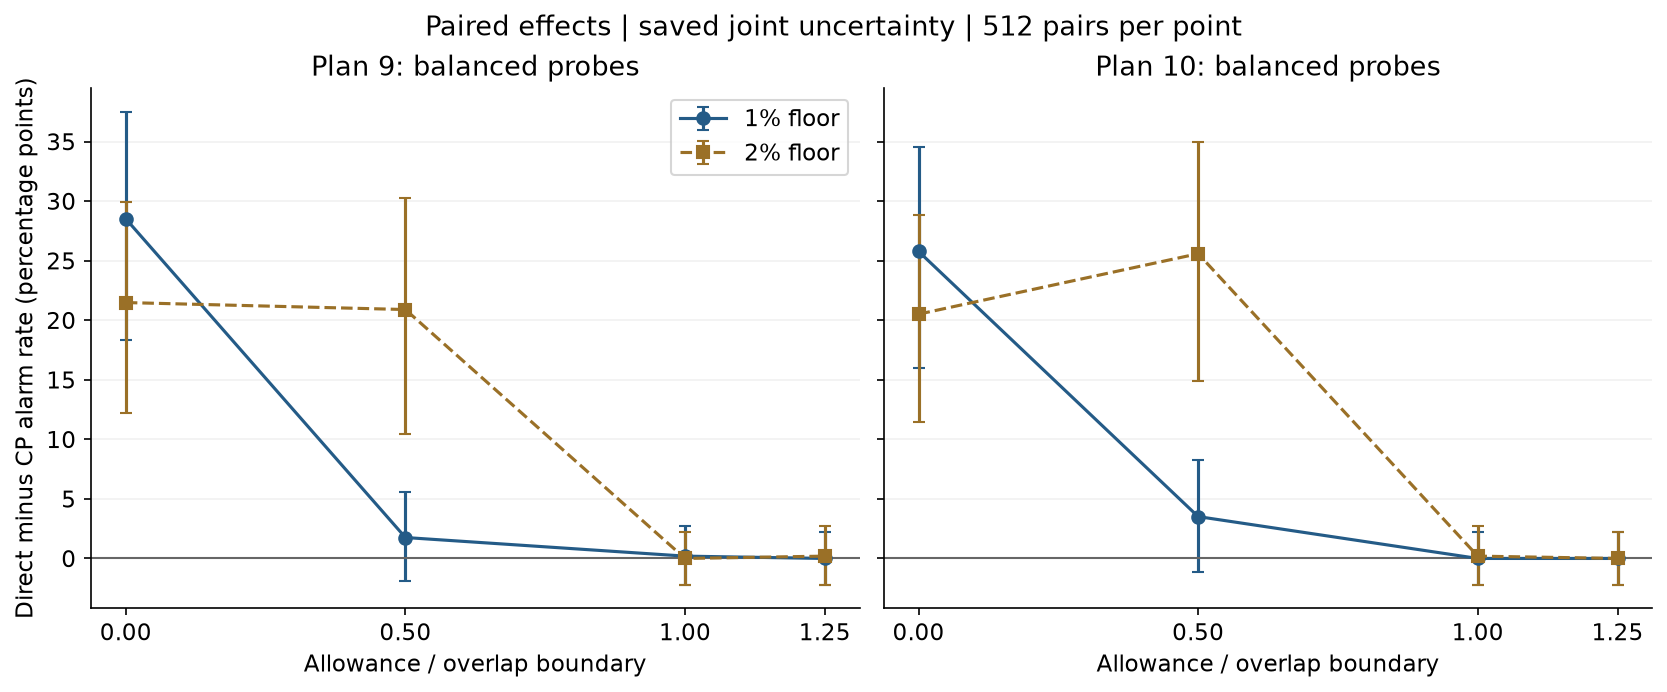

Plan 9, 1% balanced floor: exact selected values
  per-basis allowance=0.00000 QBER pp
    CP gap: 22/512 (4.30%)
    Direct pooled: 168/512 (32.81%)
    paired change=28.52 pp; joint [18.3668, 37.5037] pp
  per-basis allowance=0.24250 QBER pp
    CP gap: 3/512 (0.59%)
    Direct pooled: 12/512 (2.34%)
    paired change=1.76 pp; joint [-1.9322, 5.6131] pp
  per-basis allowance=0.48500 QBER pp
    CP gap: 0/512 (0.00%)
    Direct pooled: 1/512 (0.20%)
    paired change=0.20 pp; joint [-2.1956, 2.7152] pp
  per-basis allowance=0.60625 QBER pp
    CP gap: 0/512 (0.00%)
    Direct pooled: 0/512 (0.00%)
    paired change=0.00 pp; joint [-2.1956, 2.1956] pp
Retained attack comparisons: 96
Observed signs: positive 76 negative 3 ties 17
Joint intervals wholly above zero: 43


In [4]:
fig, axes = plt.subplots(1,2, figsize=(11,4.5), sharey=True, layout='constrained')
for ax, plan in zip(axes,(9,10)):
    for fi, floor, marker in ((1,.01,'o'),(2,.02,'s')):
        selected = [effects[(plan,fi,a,7)] for a in range(4)]
        y = np.array([e['net_alarm_rate_difference'] for e in selected])*100
        lo = np.array([e['ci_joint95'][0] for e in selected])*100
        hi = np.array([e['ci_joint95'][1] for e in selected])*100
        ax.errorbar(x,y,yerr=[y-lo,hi-y], marker=marker, capsize=3,
                    color='#245b87' if fi==1 else '#9a7027',
                    linestyle='-' if fi==1 else '--', label=f'{floor:.0%} floor')
    ax.axhline(0,color='0.4',linewidth=1)
    ax.set_title(f'Plan {plan}: balanced probes')
    ax.set_xticks(x); ax.set_xlabel('Allowance / overlap boundary'); ax.grid(axis='y',alpha=.18)
axes[0].set_ylabel('Direct minus CP alarm rate (percentage points)')
axes[0].legend()
fig.suptitle('Paired effects | saved joint uncertainty | 512 pairs per point')
show(fig,'paired-effects.png',
     'Paired direct-minus-CP effect intervals for balanced 1% and 2% floor probes. Zero is visible; gains are not established where an interval includes zero.')
print('Plan 9, 1% balanced floor: exact selected values')
for a,mult in enumerate(x):
    e=effects[(9,1,a,7)]
    print(f'  per-basis allowance={.485*mult:.5f} QBER pp')
    for m in ('clopper-pearson','direct-bernstein'):
        c=rates[(9,1,a,7,m)]
        print(f"    {labels[m]}: {c['alarms']}/512 ({c['alarm_rate']:.2%})")
    print(f"    paired change={100*e['net_alarm_rate_difference']:.2f} pp; joint [{100*e['ci_joint95'][0]:.4f}, {100*e['ci_joint95'][1]:.4f}] pp")
attack_effects=[e for e in effects.values() if e['cohort_id']>=5]
print('Retained attack comparisons:',len(attack_effects))
print('Observed signs: positive',sum(e['net_alarm_rate_difference']>0 for e in attack_effects),
      'negative',sum(e['net_alarm_rate_difference']<0 for e in attack_effects),
      'ties',sum(e['net_alarm_rate_difference']==0 for e in attack_effects))
print('Joint intervals wholly above zero:',sum(e['ci_joint95'][0]>0 for e in attack_effects))

### 5. Honest controls and stronger probes
Keep all five honest cohorts. The summary ranges below describe tested laws,
not the entire continuous honest family. The proof supplies model-wide size
control; zero observed false alarms is not zero true probability. The final
fixed stronger contrast has r=.04, hence a 2% raw-bit proxy even though its
setting's floor is 1%; it cannot stand in for floor-family sensitivity.

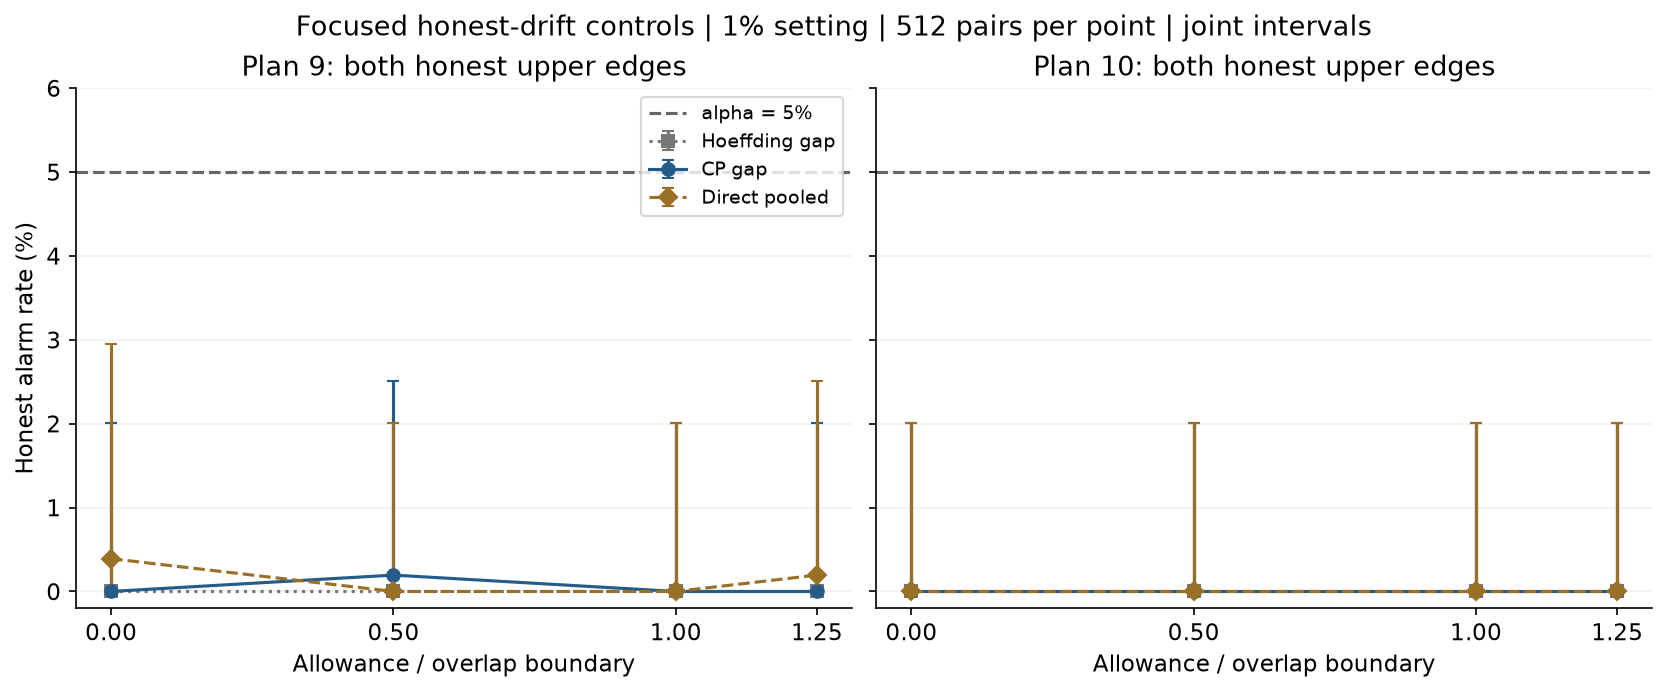

Hoeffding gap : honest alarms 0 to 0 of 512; largest joint upper endpoint 2.0081%
CP gap : honest alarms 0 to 3 of 512; largest joint upper endpoint 3.3375%
Direct pooled : honest alarms 0 to 2 of 512; largest joint upper endpoint 2.9452%
Stronger plan 9, 1% setting, half-boundary allowance:
CP gap 143 /512 27.93% joint interval [20.4279, 36.3892]
Direct pooled 444 /512 86.72% joint interval [79.837, 92.0006]


In [5]:
fig, axes = plt.subplots(1,2, figsize=(11,4.5), sharey=True, layout='constrained')
for ax,plan in zip(axes,(9,10)):
    for method in result['protocol']['methods']:
        selected=[rates[(plan,1,a,1,method)] for a in range(4)]
        y=np.array([c['alarm_rate'] for c in selected])*100
        lo=np.array([c['ci_joint95'][0] for c in selected])*100
        hi=np.array([c['ci_joint95'][1] for c in selected])*100
        color,marker,line=styles[method]
        ax.errorbar(x,y,yerr=[y-lo,hi-y],color=color,marker=marker,linestyle=line,
                    capsize=3,label=labels[method])
    ax.axhline(5,color='0.4',linestyle='--',label='alpha = 5%')
    ax.set_title(f'Plan {plan}: both honest upper edges')
    ax.set_xticks(x); ax.set_xlabel('Allowance / overlap boundary')
    ax.set_ylim(-.2,6); ax.grid(axis='y',alpha=.18)
axes[0].set_ylabel('Honest alarm rate (%)'); axes[0].legend(fontsize=9)
fig.suptitle('Focused honest-drift controls | 1% setting | 512 pairs per point | joint intervals')
show(fig,'honest-comparison.png',
     'Both honest upper-edge controls for all three rules and both plans at the 1% setting. Joint intervals and the 5% target are visible. Other honest laws remain in the summary.')
for method in result['protocol']['methods']:
    honest=[c for c in result['cells'] if c['method']==method and c['cohort_id']<5]
    print(labels[method],': honest alarms',min(c['alarms'] for c in honest),'to',
          max(c['alarms'] for c in honest),'of 512; largest joint upper endpoint',
          f"{max(c['ci_joint95'][1] for c in honest):.4%}")
print('Stronger plan 9, 1% setting, half-boundary allowance:')
for method in ('clopper-pearson','direct-bernstein'):
    c=rates[(9,1,1,8,method)]
    print(labels[method],c['alarms'],'/512',f"{c['alarm_rate']:.2%}",
          'joint interval', [round(v*100,4) for v in c['ci_joint95']])

## Takeaways
The implementation and the frozen paired evaluation support stronger
**pointwise** detection in some settings, not a uniformly dominant test.
Negative paired counts and low-power cases remain saved. No ablation was
performed, so the separate effects of pooling and direct concentration
have not been experimentally isolated. No global continuous Eve best
response, optimized allocation, noise-drift attack extension, final-key
security or publication novelty is established.

A next milestone should test the apparent advantage across Eve's continuous
basis bias and separate pooling from the change in statistic, using a frozen
fresh evaluation. Do not enlarge this run after seeing its results.
Full narrative: [direct-drift-results.md](../docs/direct-drift-results.md).
Scope: a tested real-arithmetic model/proof, not an outward-rounded or
hardware security certificate. Full notebook viewport inspection was not
available; saved figures and executed text outputs are checked separately.